In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

mensagens = [
    ("Olá João, tudo bem? Podemos marcar nossa reunião do projeto amanhã?", 0),
    ("Segue em anexo o relatório final da disciplina de banco de dados.", 0),
    ("Lembrete: a aula de aprendizado de máquina começa às 19h no laboratório.", 0),
    ("Você conseguiu rodar o script no ambiente virtual com uv?", 0),
    ("Favor confirmar presença na conferência de tecnologia até quinta.", 0),
    ("Professor, segue a entrega da atividade de programação em Python.", 0),
    ("Almoço confirmado hoje ao meio-dia na praça de alimentação?", 0),
    ("Atualização de segurança realizada com sucesso em seu servidor Linux.", 0),
    ("Preciso de ajuda com a correção dos testes de integração no backend.", 0),
    ("Bom dia! Poderia revisar a documentação da API antes do deploy?", 0),
    ("Seu pacote dos Correios chegou na portaria do condomínio.", 0),
    ("Reunião de alinhamento da squad reagendada para sexta-feira.", 0),
    ("URGENTE! Seu cartão de crédito foi clonado. Clique no link para desbloquear agora.", 1),
    ("Parabéns! Você ganhou um prêmio de 50 mil reais no sorteio do PIX. Resgate já!", 1),
    ("Aviso bancário: sua conta possui pendência crítica. Acesse o link seguro imediatamente.", 1),
    ("Empréstimo pré-aprovado sem consulta ao SPC e Serasa com taxa zero. Clique aqui.", 1),
    ("Você foi selecionado para receber uma recompensa exclusiva. Cadastre seu cartão.", 1),
    ("Oferta imperdível! Compre o produto com 90 por cento de desconto só hoje.", 1),
    ("ATENÇÃO: Sua chave PIX precisa de recadastramento urgente para evitar bloqueio.", 1),
    ("Trabalhe de casa e ganhe 5 mil reais por semana sem experiência. Saiba mais.", 1),
    ("Ganhe seguidores e curtidas ilimitadas no seu perfil agora mesmo de graça.", 1),
    ("Último aviso! Seu saldo promocional expira em 1 hora. Clique para resgatar.", 1),
    ("Sua fatura do cartão está atrasada. Pague via PIX com desconto especial no link.", 1),
    ("Parabéns cliente! Seu número foi premiado na promoção anual da loja.", 1)
]

df = pd.DataFrame(mensagens, columns=["texto", "rotulo"])
print(f"Total de mensagens: {len(df)}")

Total de mensagens: 24


In [2]:
X = df["texto"]
y = df["rotulo"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print(f"Treino: {len(X_treino)} | Teste: {len(X_teste)}")

Treino: 16 | Teste: 8


In [3]:
from sklearn.feature_extraction.text import CountVectorizer

stop_words_pt = ["de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com", "não", "uma", "os", "no", "se", "na", "por", "mais", "as", "dos", "como", "mas", "ao", "ele", "das", "à", "seu", "sua", "ou", "quando", "muito", "foi"]

vetorizador = CountVectorizer(lowercase=True, stop_words=stop_words_pt)

X_treino_vec = vetorizador.fit_transform(X_treino)
X_teste_vec = vetorizador.transform(X_teste)

print(f"Vocabulário aprendido: {len(vetorizador.get_feature_names_out())} palavras.")

Vocabulário aprendido: 115 palavras.


In [4]:
from sklearn.naive_bayes import MultinomialNB

classificador_nb = MultinomialNB(alpha=1.0)
classificador_nb.fit(X_treino_vec, y_treino)
print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


=== RELATÓRIO DE CLASSIFICAÇÃO ===
              precision    recall  f1-score   support

     Ham (0)       1.00      0.75      0.86         4
    Spam (1)       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8



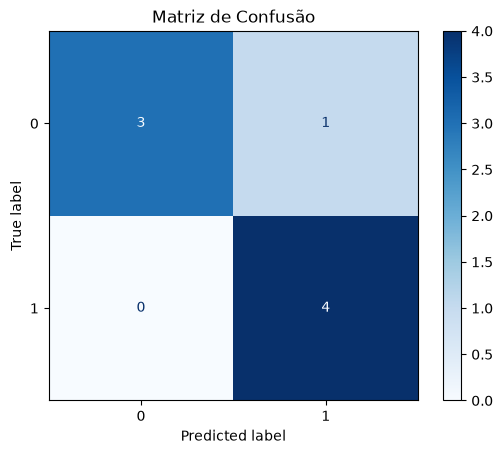

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred = classificador_nb.predict(X_teste_vec)

print("=== RELATÓRIO DE CLASSIFICAÇÃO ===")
print(classification_report(y_teste, y_pred, target_names=["Ham (0)", "Spam (1)"]))

ConfusionMatrixDisplay.from_estimator(classificador_nb, X_teste_vec, y_teste, cmap='Blues')
plt.title("Matriz de Confusão")
plt.show()

In [6]:
novas_mensagens = [
    "Parabéns! Clique no link e resgate seu prêmio em dinheiro agora via PIX.",
    "Boa tarde, professor. Gostaria de tirar uma dúvida sobre a entrega da atividade."
]

X_novas_vec = vetorizador.transform(novas_mensagens)
previsoes = classificador_nb.predict(X_novas_vec)

for msg, pred in zip(novas_mensagens, previsoes):
    classe = "SPAM" if pred == 1 else "HAM (Legítimo)"
    print(f"Mensagem: '{msg}' -> Classificado como: {classe}")

Mensagem: 'Parabéns! Clique no link e resgate seu prêmio em dinheiro agora via PIX.' -> Classificado como: SPAM
Mensagem: 'Boa tarde, professor. Gostaria de tirar uma dúvida sobre a entrega da atividade.' -> Classificado como: HAM (Legítimo)


In [ ]:
from sklearn.pipeline import Pipeline

pipeline_spam = Pipeline([
    ("vetorizador", CountVectorizer(lowercase=True, stop_words=stop_words_pt)),
    ("classificador", MultinomialNB(alpha=1.0))
])

pipeline_spam.fit(X_treino, y_treino)
previsoes_pipe = pipeline_spam.predict(novas_mensagens)
print(f"Previsões via Pipeline: {previsoes_pipe}")

Previsões via Pipeline: [1 0]
